Ben Testing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import rc
import astropy.units as u
import astropy.coordinates as coord
import astropy as ap

df1 = pd.read_csv("globular_clusters.csv")
df1 = df1[0:-3]
harris_p1 = pd.read_csv('HarrisPartI.csv')
harris_p2 = pd.read_csv('HarrisPartII.csv')
harris_p3 = pd.read_csv('HarrisPartIII.csv')




In [2]:

df1["Age0"]=df1["Age"].str.split(" ±").str[0].astype(float)
df1["Age_error"]=df1["Age"].str.split(" ±").str[1].astype(float)
df1["Name"] = "NGC " + df1["NGC"].astype(float).astype("Int64").astype(str)
harris_p2["ID"] = harris_p2["ID"].astype(str).str.strip().str.upper()
df1["Name"] = df1["Name"].astype(str).str.strip().str.upper()


In [3]:
rc('text', usetex=False)
R_gc = pd.to_numeric(harris_p1['R_gc'],errors='coerce')
X = pd.to_numeric(harris_p1['X'],errors='coerce')
Y = pd.to_numeric(harris_p1['Y'],errors='coerce')
Z = pd.to_numeric(harris_p1['Z'],errors='coerce')
Ra = pd.to_numeric(harris_p1['RA'],errors='coerce')
Dec = pd.to_numeric(harris_p1['DEC'],errors='coerce')
R_Sun = pd.to_numeric(harris_p1['R_Sun'],errors='coerce')
sig_v = pd.to_numeric(harris_p3['sig_v'],errors='coerce')
v_r = pd.to_numeric(harris_p3['v_r'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
rho_0 = pd.to_numeric(harris_p3['rho_0'],errors='coerce')
mu_V = pd.to_numeric(harris_p3['mu_V'],errors='coerce')
c = pd.to_numeric(harris_p3['c'],errors='coerce')
BmV = pd.to_numeric(harris_p2['B-V'],errors='coerce')
ellip = pd.to_numeric(harris_p2['ellip'],errors='coerce')
r_c = pd.to_numeric(harris_p3['r_c'],errors='coerce')
r_h = pd.to_numeric(harris_p3['r_h'],errors='coerce')
M_V = pd.to_numeric(harris_p2['M_V,t'],errors='coerce')
V_t = pd.to_numeric(harris_p2['V_t'],errors='coerce')
wt = pd.to_numeric(harris_p2['wt'],errors='coerce')
L = pd.to_numeric(harris_p1['L'],errors='coerce')
B = pd.to_numeric(harris_p1['B'],errors='coerce')
v_LSR= pd.to_numeric(harris_p3['v_LSR'],errors='coerce')
mask = mtlc > -0.8
log_tc= pd.to_numeric(harris_p3['lg_tc'],errors='coerce')
log_th= pd.to_numeric(harris_p3['lg_th'],errors='coerce')
## Copied of Tobias
VmR = pd.to_numeric(harris_p2['V-R'],errors='coerce')
UmB = pd.to_numeric(harris_p2['U-B'],errors='coerce')
VmI = pd.to_numeric(harris_p2['V-I'],errors='coerce')
V_hb = pd.to_numeric(harris_p2['V_HB'],errors='coerce')
## Correct colour values for foreground reddening
E_BmV = pd.to_numeric(harris_p2['E(B-V)'],errors='coerce')
BmV0=BmV - E_BmV
VmR0=VmR - 0.72*E_BmV
VmI0=VmI - 1.24*E_BmV
UmB0=UmB - 0.72*E_BmV
#Coefficients calculated from Cardelli et al. 1989, ApJ, 345, 245
Age = pd.to_numeric(df1['Age0'],errors='coerce')
Age_e = pd.to_numeric(df1['Age_error'],errors='coerce') 
#Convert RA and DEC to degrees

Ra_rad = coord.Angle(Ra, unit=u.hourangle).rad
Dec_rad = coord.Angle(Dec, unit=u.degree).rad


In [4]:
## Merge age and harris dataframes
merged_df = harris_p2.merge(
    df1[["Name", "Age0"]],
    left_on="ID",
    right_on="Name",
    how="left",
    validate="many_to_one"
)
merged_df = merged_df.merge(
    harris_p1[["ID", "R_gc"]],
    on="ID",
    how="left",
    validate="many_to_one"
)
merged_df = merged_df.merge(
    harris_p1[["ID", "X", "Y", "Z", "RA", "DEC", "R_Sun"]],
    on="ID",
    how="left",
    validate="many_to_one"
)

merged_df['RA'] = coord.Angle(merged_df['RA'], unit=u.hourangle).rad
merged_df['DEC'] = coord.Angle(merged_df['DEC'], unit=u.degree).rad



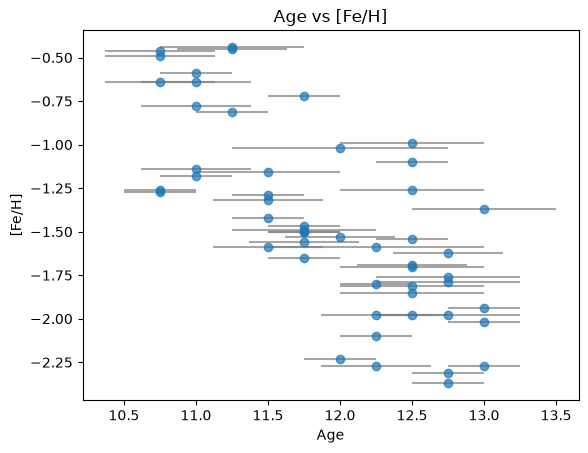

In [5]:
#Plot Age vs Mtlc
Age_df = merged_df.dropna(subset=['Age0', '[Fe/H]', '[Fe/H]'])
Age_df['[Fe/H]']= pd.to_numeric(Age_df['[Fe/H]'],errors='coerce')

plt.figure()
plt.errorbar(Age_df['Age0'], Age_df['[Fe/H]'], xerr=Age_e, marker='o', linestyle='', ecolor='gray', alpha=0.7)
plt.xlabel('Age')
plt.ylabel('[Fe/H]')
plt.title('Age vs [Fe/H]')


plt.show()

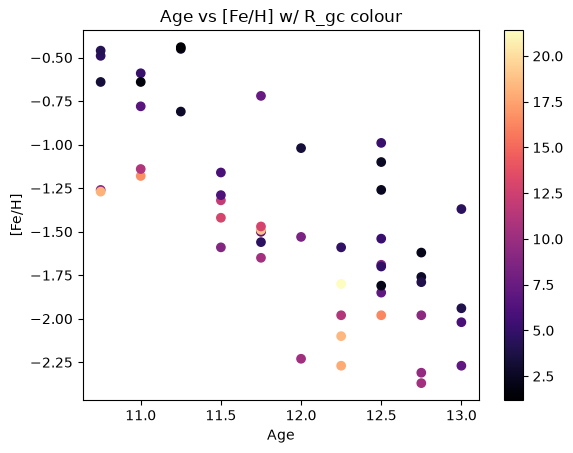

In [ ]:
#Plot Age vs Mtlc with Radius Colour
Age_df = merged_df.dropna(subset=['Age0', '[Fe/H]', '[Fe/H]'])
Age_df['[Fe/H]']= pd.to_numeric(Age_df['[Fe/H]'],errors='coerce')
Age_df['R_gc']= pd.to_numeric(Age_df['R_gc'],errors='coerce')



plt.figure()
plt.scatter(Age_df['Age0'], Age_df['[Fe/H]'], c=Age_df["R_gc"], cmap='magma')
plt.colorbar()
plt.xlabel('Age')
plt.ylabel('[Fe/H]')
plt.title('Age vs [Fe/H] w/ R_gc colour')
plt.scatter()

plt.show()

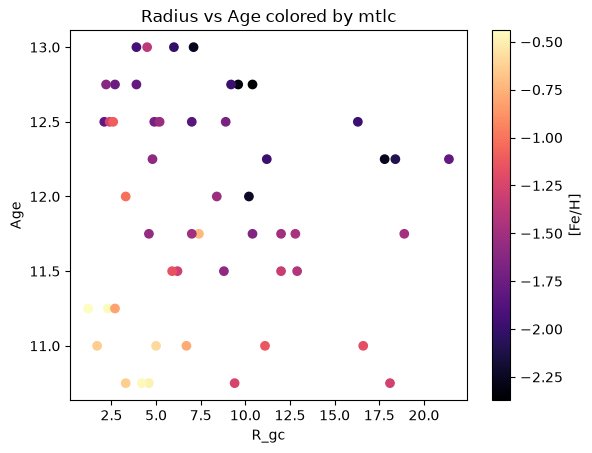

In [7]:
#Plot Age vs R_gc with mtlc colour
plt.figure()
plt.scatter(Age_df['R_gc'], Age_df['Age0'], c=Age_df['[Fe/H]'], cmap='magma', vmin=Age_df['[Fe/H]'].min(), vmax=Age_df['[Fe/H]'].max())
plt.xlabel('R_gc')
plt.ylabel('Age')
plt.title('Radius vs Age colored by mtlc')
plt.colorbar(label='[Fe/H]')

plt.show()
# Shows that metal rich clusters are younger and close to the centre. As you increase R or age, you decrease mtlc.
# Age has bigger effect in mtlc than R_gc. This is because the age of the cluster is more important in determining its metallicity than its distance from the galactic center.

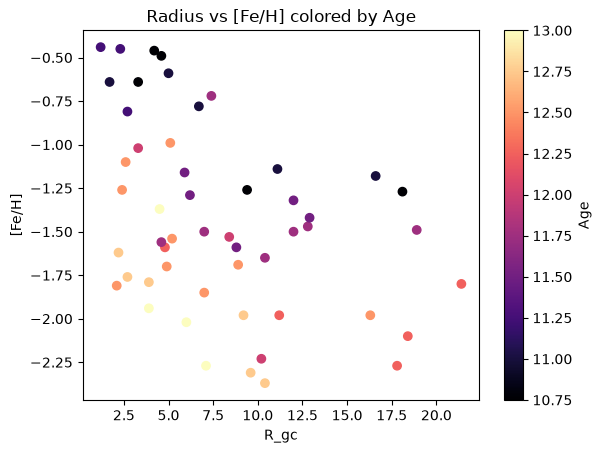

In [8]:
#Plot mtlc vs R_gc with Age colour
plt.figure()
plt.scatter(Age_df['R_gc'], Age_df['[Fe/H]'], c=Age_df['Age0'], cmap='magma', vmin=Age_df['Age0'].min(), vmax=Age_df['Age0'].max())
plt.xlabel('R_gc')
plt.ylabel('[Fe/H]')
plt.title('Radius vs [Fe/H] colored by Age')
plt.colorbar(label='Age')

plt.show()
# Shows that metal rich clusters are younger and close to the centre. As you increase R or age, you decrease mtlc.
# Age has bigger effect in mtlc than R_gc. This is because the age of the cluster is more important in determining its metallicity than its distance from the galactic center.

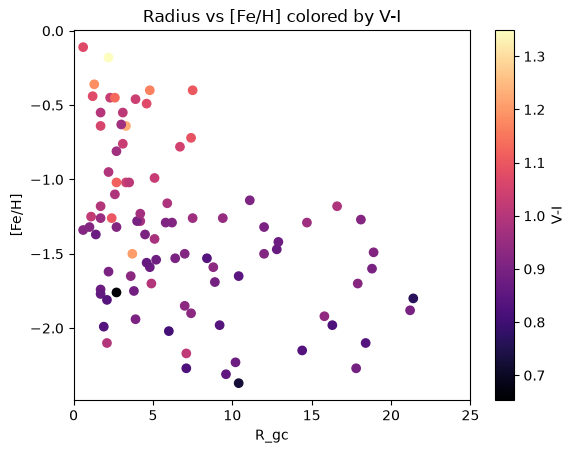

In [ ]:
#Plot mtlc vs R_gc with V-I colour
plt.figure()
plt.scatter(VmI0, mtlc, c=R_gc, cmap='magma', vmin=R_gc.min(), vmax=25)
plt.xlabel('V-I')
plt.ylabel('[Fe/H]')
plt.title('Colour vs [Fe/H] colored by Galactocentric radius)
plt.colorbar(label='V-I')
plt.xlim(0, 25)


plt.show()



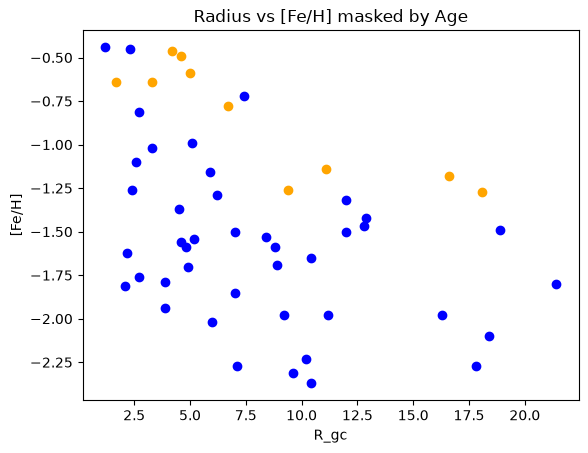

In [9]:
#Plot mtlc vs R_gc with Age masking

mask_num = 11

mask1 = Age_df["Age0"]> mask_num
mask2 = Age_df["Age0"]<=mask_num

plt.figure()
plt.scatter(Age_df['R_gc'][mask1], Age_df['[Fe/H]'][mask1], c="blue")
plt.scatter(Age_df['R_gc'][mask2], Age_df['[Fe/H]'][mask2], c="orange")
plt.xlabel('R_gc')
plt.ylabel('[Fe/H]')
plt.title('Radius vs [Fe/H] masked by Age')


plt.show()
# Shows that metal rich clusters are younger and close to the centre. As you increase R or age, you decrease mtlc.
# Age has bigger effect in mtlc than R_gc. This is because the age of the cluster is more important in determining its metallicity than its distance from the galactic center.

In [10]:
print(Age_df["Age0"].head)

<bound method NDFrame.head of 0      11.75
1      11.50
2      10.75
4      10.75
9      11.00
15     11.00
18     11.50
21     12.25
24     12.00
25     12.50
26     12.25
27     12.25
29     11.75
30     12.50
32     12.50
39     11.50
40     10.75
43     12.25
47     11.50
48     12.25
49     12.75
52     12.00
54     12.00
56     13.00
59     11.75
67     11.25
69     12.75
75     10.75
78     11.00
81     12.50
89     13.00
99     10.75
105    12.75
110    12.50
121    11.75
122    11.25
125    11.00
127    11.25
128    12.50
130    12.75
133    11.75
134    12.50
135    12.50
137    12.50
139    12.75
143    13.00
146    11.00
148    11.75
149    11.50
151    12.75
152    11.75
153    13.00
Name: Age0, dtype: float64>


In [11]:
#Create 3d map of Clusters using astropy
Ra = merged_df['RA'].to_numpy(dtype=float)*u.rad
Dec = merged_df['DEC'].to_numpy(dtype=float)*u.rad
R_sun = merged_df['R_Sun'].to_numpy(dtype=float)*u.kpc
heli_coords = coord.SkyCoord(ra=Ra, dec=Dec, distance=R_sun, frame='icrs')
GC_coords = heli_coords.transform_to(coord.Galactocentric())
GC_cart = GC_coords.cartesian
GC_cart


<CartesianRepresentation (x, y, z) in kpc
    [(-6.26091873e+00, -2.58267656e+00, -3.15980646e+00),
     (-8.22915695e+00,  4.62522504e-02, -8.87843437e+00),
     (-5.02751751e+00, -5.06910508e+00, -6.19920938e+00),
     (            nan,             nan,             nan),
     (-8.06082354e+00, -1.00069197e+01, -1.28457387e+01),
     (            nan,             nan,             nan),
     (-2.48500489e+01, -8.00672707e+01, -9.22412921e+01),
     (            nan,             nan,             nan),
     (            nan,             nan,             nan),
     (-1.24029193e+01, -8.94322561e+00, -6.91477623e+00),
     (-1.57735377e+01, -8.25423098e+00, -6.28247174e+00),
     (-1.24134293e+01, -9.45620806e+00, -2.94627518e+00),
     (-8.27431674e+01, -4.81196363e-01,  3.54355689e+01),
     (            nan,             nan,             nan),
     (            nan,             nan,             nan),
     (-6.13818435e+00, -9.20305548e+00, -1.85759054e+00),
     (-5.22683050e+00, -7.0867

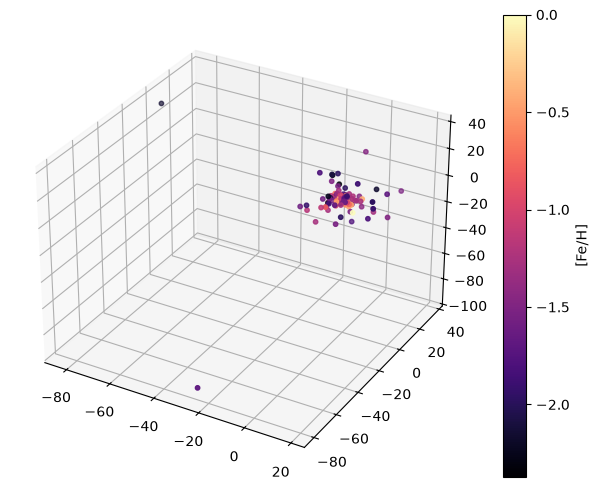

In [12]:
x_gc=GC_cart.x.value
y_gc=GC_cart.y.value
z_gc=GC_cart.z.value

x_gc_Sol=-coord.Galactocentric().galcen_distance
y_gc_Sol=0
z_gc_Sol=coord.Galactocentric().z_sun


#3d Map of Mtlc
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

#Plot sun on axes

sc=ax.scatter(x_gc, y_gc, z_gc, c=mtlc, s=10, marker='o', cmap='magma', vmin=mtlc.min(), vmax=mtlc.max())
# Sun Plot: ax.scatter(x_gc_Sol, y_gc_Sol, z_gc_Sol, c='yellow', s=200, marker='*', label='Sun')
#ax.set_xlim(-20, 20)
#ax.set_ylim(-20, 20)
#ax.set_zlim(-20, 20)
plt.colorbar(sc, label='[Fe/H]')
plt.show()

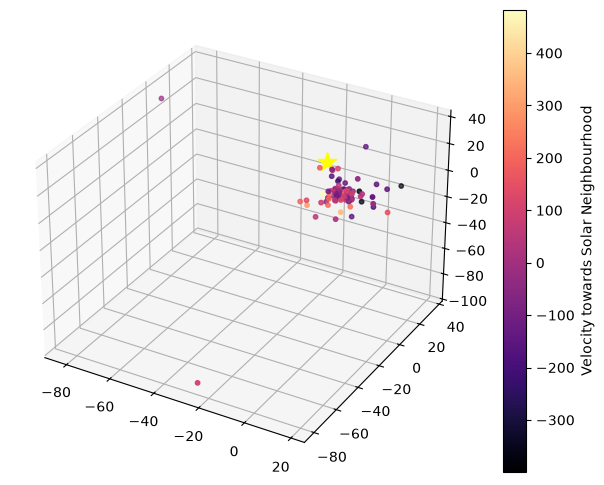

In [13]:
#3d Map of Velocity towards sun
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

sc=ax.scatter(x_gc, y_gc, z_gc, c=v_LSR, s=10, marker='o', cmap='magma', vmin=v_LSR.min(), vmax=v_LSR.max())
ax.scatter(x_gc_Sol, y_gc_Sol, z_gc_Sol, c='yellow', s=200, marker='*', label='Sun')
#ax.set_xlim(-20, 20)
#ax.set_ylim(-20, 20)
#ax.set_zlim(-20, 20)
plt.colorbar(sc, label='Velocity towards Solar Neighbourhood')
plt.show()

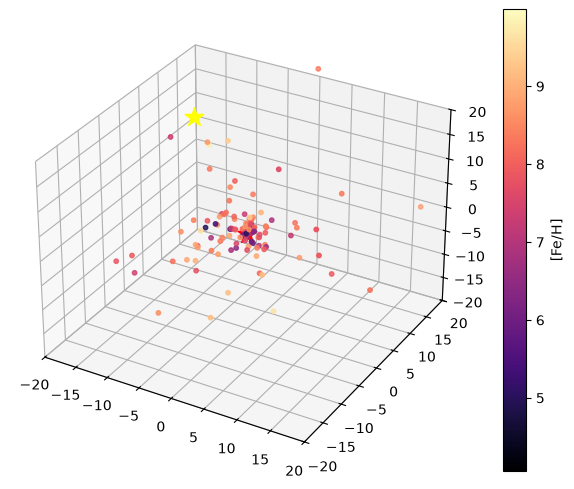

In [14]:
#3d Map of Mtlc
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

#Plot sun on axes

sc=ax.scatter(x_gc, y_gc, z_gc, c=log_tc, s=10, marker='o', cmap='magma', vmin=log_tc.min(), vmax=log_tc.max())
# Sun Plot: 
ax.scatter(x_gc_Sol, y_gc_Sol, z_gc_Sol, c='yellow', s=200, marker='*', label='Sun')
# Galactic Center Plot: 
ax.scatter(0, 0, 0, c='red', s=200, marker='*', label='Galactic Center')
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_zlim(-20, 20)
plt.colorbar(sc, label='[Fe/H]')
plt.show()

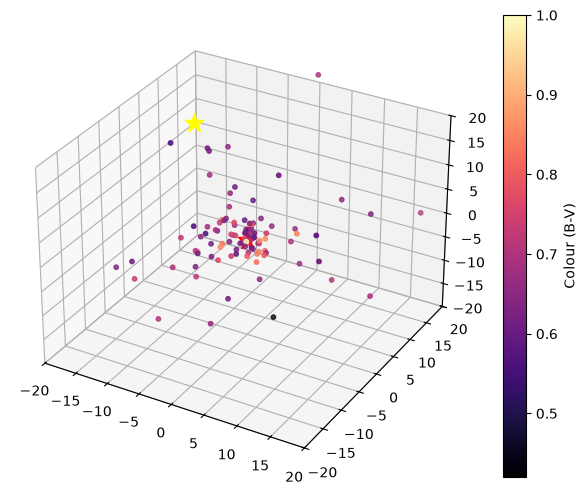

In [15]:
#3d Map of Colour of Stars
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

sc=ax.scatter(x_gc, y_gc, z_gc, c=BmV0, s=10, marker='o', cmap='magma', vmin=BmV0.min(), vmax=1)
# Sun Plot: 
ax.scatter(x_gc_Sol, y_gc_Sol, z_gc_Sol, c='yellow', s=200, marker='*', label='Sun')
# Galactic Center Plot: 
ax.scatter(0, 0, 0, c='red', s=200, marker='*', label='Galactic Center')
ax.set_xlim(-20, 20)
ax.set_ylim(-20, 20)
ax.set_zlim(-20, 20)
plt.colorbar(sc, label='Colour (B-V)')
plt.show()

# We see that as we get further from the GC, B-V tends to decrease, indicating a Bluer colour. This is consistent with lower ages.

Text(0.5, 1.0, '')

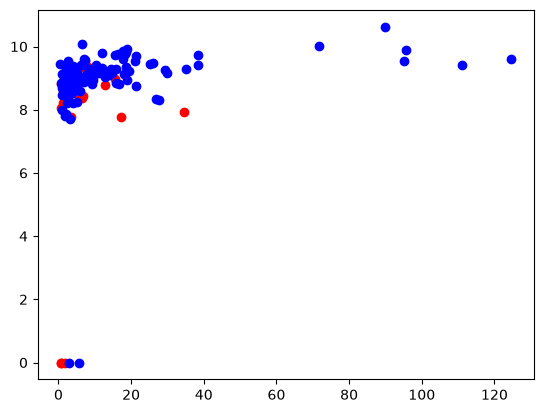

In [16]:
mask_num = -0.8

mask2 = mtlc < mask_num
mask1 = mtlc >= mask_num
plt.figure()
plt.scatter(R_gc[mask1], log_th[mask1], color='r', label='R_gc >= 10 kpc')
plt.scatter(R_gc[mask2], log_th[mask2], color='b', label='R_gc < 10 kpc')
plt.xlabel('')
plt.ylabel('')
plt.title('')

Text(0.5, 1.0, 'Distance from GC vs radial velocity from Sun coloured by metallicity')

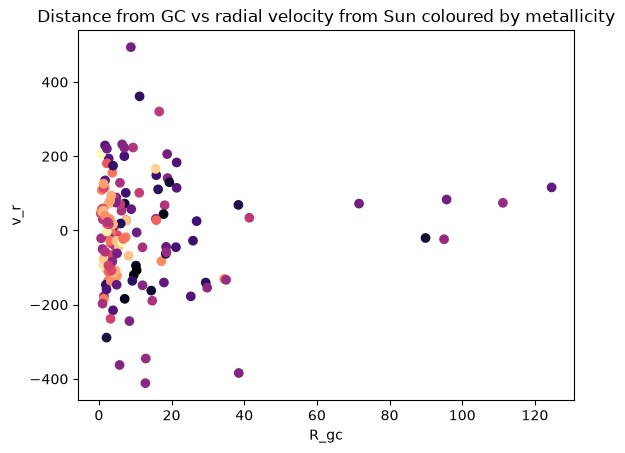

In [17]:
plt.figure()
plt.scatter(R_gc, v_r, c=mtlc, cmap='magma')
plt.xlabel('R_gc')
plt.ylabel('v_r')
plt.title('Distance from GC vs radial velocity from Sun coloured by metallicity')

Text(0.5, 1.0, '')

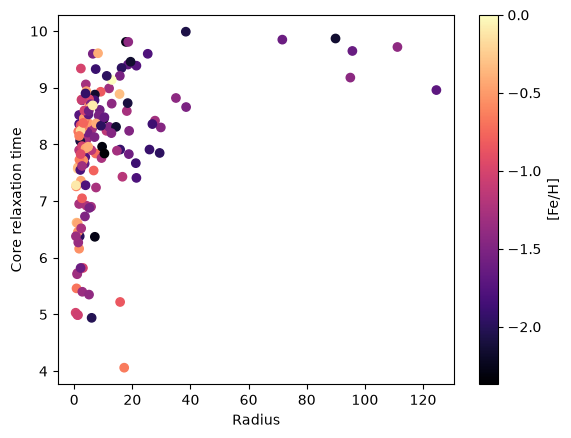

In [18]:
plt.figure()
plt.scatter(R_gc, log_tc, c=mtlc, cmap='magma')
plt.colorbar(label='[Fe/H]')
plt.xlabel('Radius')
plt.ylabel('Core relaxation time')
plt.title('')


In [ ]:
#Identify 6 outliers on R_gc diagram
R_Mask_60 = R_gc >= 60
df_filtered0 = harris_p1[R_Mask_60]
df_filtered1=harris_p2[R_Mask_60]

p2 = harris_p2[["ID", "[Fe/H]"]].copy()

# Standardise IDs in both dataframes
df_filtered0["ID"] = (
    df_filtered0["ID"].astype(str).str.strip().str.upper()
)
p2["ID"] = p2["ID"].astype(str).str.strip().str.upper()

df_filtered = df_filtered0.merge(
    p2,
    on="ID",
    how="left",
    validate="many_to_one"
)
mean_mtlc_acc = pd.to_numeric(df_filtered['[Fe/H]'], errors = "coerce").mean()






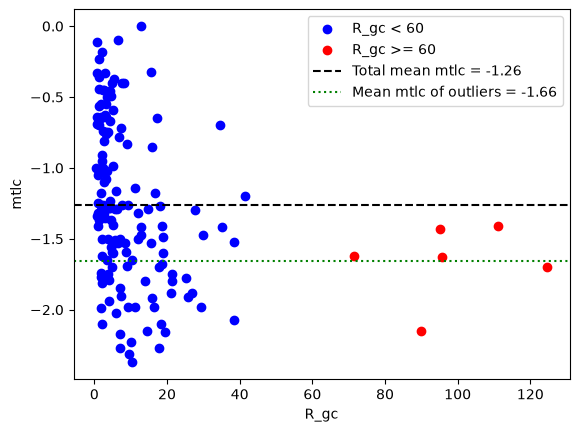

In [77]:
#Mask top 6 clusters in R
mask_low = R_gc < 60
mask_high = R_gc >= 60

plt.scatter(R_gc[mask_low], mtlc[mask_low],
            color="blue", label="R_gc < 60")

plt.scatter(R_gc[mask_high], mtlc[mask_high],
            color="red", label="R_gc >= 60")

# Add line for avg mtlc
plt.axhline(mtlc.mean(), color="black", linestyle="--",
            label=f"Total mean mtlc = {mtlc.mean():.2f}")

plt.xlabel("R_gc")
plt.ylabel("mtlc")
# Add horizontal line
plt.axhline(
    mean_mtlc_acc,
    color="green",
    linestyle=":",
    label=f"Mean mtlc of outliers = {mean_mtlc_acc:.2f}"
)

plt.legend()
plt.show()

Text(0, 0.5, 'mtlc')

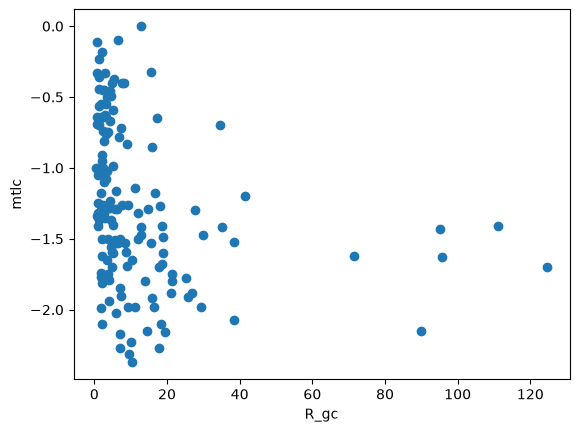

Text(0.5, 1.0, 'Ellipticity against distance from GC')

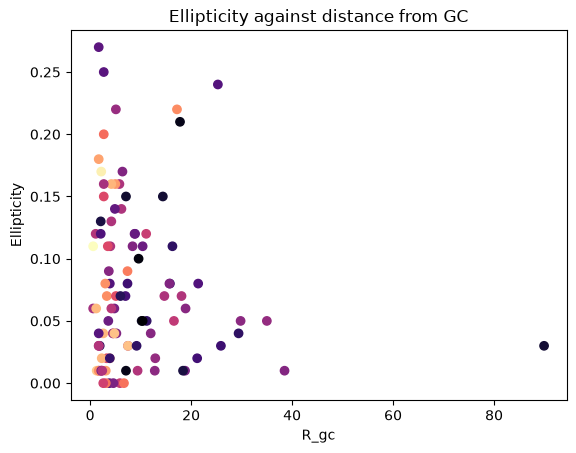

In [ ]:
#R_gc vs Ellipticity
plt.figure()
plt.scatter(R_gc, ellip, c = mtlc, cmap= "magma")
plt.xlabel('R_gc')
plt.ylabel('Ellipticity')
plt.title('Ellipticity against distance from GC')

In [33]:
harris_p2.loc[harris_p2["ID"] == "PAL 14"]

,ID,[Fe/H],wt,E(B-V),V_HB,(m-M)V,V_t,"M_V,t",U-B,B-V,V-R,V-I,spt,ellip
45,PAL 14,-1.62,4,0.04,20.1,19.54,14.74,-4.8,,,,,,


In [78]:
df_filtered

,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,[Fe/H]
0,AM 1,E 1,03:55:02.3,-49:36:55,258.34,-48.47,123.3,124.6,-16.5,-80.1,-92.3,-1.7
1,ERIDANUS,NaN,04:24:44.5,-21:11:13,218.10,-41.33,90.1,95.0,-53.2,-41.7,-59.5,-1.43
2,NGC 2419,NaN,07:38:08.47,+38:52:56.8,180.37,25.24,82.6,89.9,-74.7,-0.5,35.2,-2.15
3,PAL 3,NaN,10:05:31.9,+00:04:18,240.15,41.86,92.5,95.7,-34.3,-59.7,61.7,-1.63
4,PAL 4,NaN,11:29:16.80,+28:58:24.9,202.31,71.80,108.7,111.2,-31.4,-12.9,103.2,-1.41
5,PAL 14,AvdB,16:11:00.6,+14:57:28,28.74,42.19,76.5,71.6,49.7,27.3,51.4,-1.62


,ID,Name,RA,DEC,L,B,R_Sun,R_gc,X,Y,Z,[Fe/H],Age
0,AM 1,E 1,03:55:02.3,-49:36:55,258.34,-48.47,123.3,124.6,-16.5,-80.1,-92.3,-1.7,11.12
1,ERIDANUS,NaN,04:24:44.5,-21:11:13,218.10,-41.33,90.1,95.0,-53.2,-41.7,-59.5,-1.43,11.50
2,NGC 2419,NaN,07:38:08.47,+38:52:56.8,180.37,25.24,82.6,89.9,-74.7,-0.5,35.2,-2.15,12.45
3,PAL 3,NaN,10:05:31.9,+00:04:18,240.15,41.86,92.5,95.7,-34.3,-59.7,61.7,-1.63,11.00
4,PAL 4,NaN,11:29:16.80,+28:58:24.9,202.31,71.80,108.7,111.2,-31.4,-12.9,103.2,-1.41,11.00
5,PAL 14,AvdB,16:11:00.6,+14:57:28,28.74,42.19,76.5,71.6,49.7,27.3,51.4,-1.62,10.00


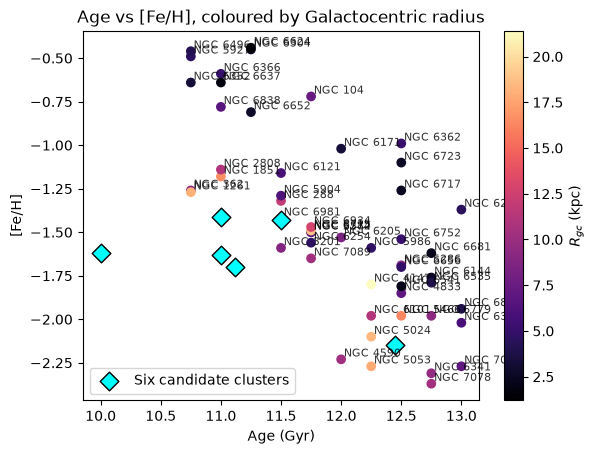

In [105]:

filtered_age_list = [11.12, 11.5, 12.45, 11, 11, 10]
#Ages obtained are JUST INDICAIVE and obtained from WIKIPEDIA. Better sourced and cited results will be found if used in assignment.
df_filtered["Age"] = filtered_age_list


plt.figure()
sc = plt.scatter(Age_df['Age0'], Age_df['[Fe/H]'], c=Age_df["R_gc"], cmap='magma')
plt.scatter(
    df_filtered['Age'],
    pd.to_numeric(df_filtered['[Fe/H]'], errors='coerce'),
    color='cyan',
    edgecolors='black',
    linewidths=1,
    s=90,
    marker='D',
    label='Six candidate clusters',
    zorder=3
)
for _, row in Age_df.iterrows():
    plt.annotate(
        row["ID"],
        (row["Age0"], row["[Fe/H]"]),
        fontsize=8,
        alpha=0.8,
        xytext=(2, 2),
        textcoords="offset points"
    )

plt.colorbar(sc, label='$R_{gc}$ (kpc)')
plt.xlabel('Age (Gyr)')
plt.ylabel('[Fe/H]')
plt.title('Age vs [Fe/H], coloured by Galactocentric radius')
plt.legend()
plt.show()
plt.show()

In [107]:
#Check which dots refer to which clsuters

Age_df["[Fe/H]"] = pd.to_numeric(Age_df["[Fe/H]"])
#mask_check1 = Age_df[Age_df["[Fe/H]"]<-2]
mask_check2 = Age_df[Age_df["Age0"]<11]
mask_check2


,ID,[Fe/H],wt,E(B-V),V_HB,(m-M)V,V_t,"M_V,t",U-B,B-V,...,ellip,Name,Age0,R_gc,X,Y,Z,RA,DEC,R_Sun
2,NGC 362,-1.26,5,0.05,15.44,14.83,6.4,-8.43,0.16,0.77,...,0.01,NGC 362,10.75,9.4,3.1,-5.1,-6.2,0.275926,-1.236544,8.6
4,NGC 1261,-1.27,3,0.01,16.70,16.09,8.29,-7.8,0.13,0.72,...,0.07,NGC 1261,10.75,18.1,0.1,-10.0,-12.9,0.838937,-0.963705,16.3
40,NGC 5927,-0.49,5,0.45,16.55,15.82,8.01,-7.81,0.85,1.31,...,0.04,NGC 5927,10.75,4.6,6.4,-4.2,0.7,4.049214,-0.884411,7.7
75,NGC 6352,-0.64,5,0.22,15.13,14.43,7.96,-6.47,0.64,1.06,...,0.07,NGC 6352,10.75,3.3,5.3,-1.8,-0.7,4.561790,-0.845126,5.6
99,NGC 6496,-0.46,3,0.15,16.47,15.74,8.54,-7.2,0.45,0.98,...,0.16,NGC 6496,10.75,4.2,10.9,-2.3,-2.0,4.708293,-0.772586,11.3


Text(0.5, 1.0, '')

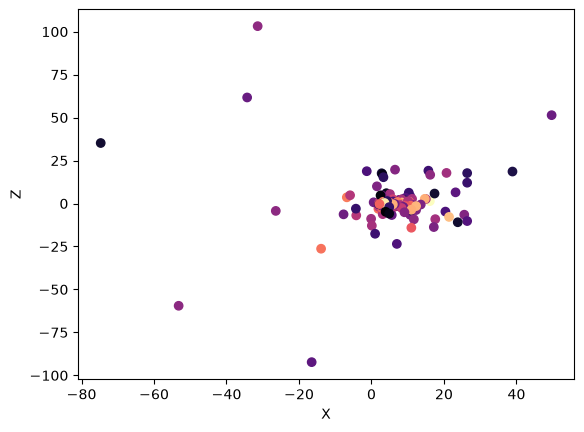

In [ ]:
plt.figure()
plt.scatter(X, Z, c=mtlc, cmap='magma')
plt.xlabel('X')
plt.ylabel('Z')
plt.title('')


In [112]:
mask_check3 = abs(Z)>20
print(merged_df[mask_check3])


            ID [Fe/H]  wt  E(B-V)   V_HB  (m-M)V    V_t  M_V,t   U-B   B-V  \
3    WHITING 1   -0.7   1    0.03  18.18   17.49  15.03  -2.46               
6         AM 1   -1.7   2    0.00  21.00   20.45  15.72  -4.73        0.72   
7     ERIDANUS  -1.43   4    0.02  20.42   19.83   14.7  -5.13        0.79   
12    NGC 2419  -2.15   2    0.08  20.31   19.83  10.41  -9.42  0.07  0.66   
17       PAL 3  -1.63   5    0.04  20.51   19.95  14.26  -5.69               
19       PAL 4  -1.41   5    0.01  20.80   20.21   14.2  -6.01               
20        KO 1          0    0.01  19.10   18.45   17.1  -1.35               
45      PAL 14  -1.62   4    0.04  20.10   19.54  14.74   -4.8               
156   NGC 7492  -1.78   5    0.00  17.63   17.10  11.29  -5.81  0.23  0.42   

     ... ellip Name Age0   R_gc     X     Y     Z        RA       DEC  R_Sun  
3    ...        NaN  NaN    NaN   NaN   NaN   NaN       NaN       NaN    NaN  
6    ...        NaN  NaN  124.6 -16.5 -80.1 -92.3  1.025548 -